# Few-parameter flow for 2D $\phi^4$: main results at $L = 8, 12, 16$

This notebook reruns the main pipeline of the paper on a laptop CPU and compares the result with long HMC chains.

For every lattice size $L$ and coupling $\kappa$ it

1. generates 1024 fitting configurations with HMC and embedded Wolff cluster updates,
2. fixes the double-well zero-mode base distribution from $\langle y^2\rangle$ and $\langle y^4\rangle$ of these configurations,
3. fits the 16 velocity coefficients at 15 time nodes by linear least squares (zero modes paired by magnitude),
4. draws independent proposals with exact $\log q$ and computes the weights $w = e^{-S}/q$,
5. estimates $\langle|M|\rangle$, $\chi/V=\langle M^2\rangle$ and $U_4$ by reweighting (IS) and by an IMH chain,

and reports the effective sample size (ESS), $\mathrm{Var}(\log w)/V$ and the IMH acceptance.
The HMC reference values (chains of $2\times10^6$ trajectories) are read from `hmc_reference_L8_12_16.json`.

**Runtime.** With 4 threads, one $(L,\kappa)$ point takes about 1 minute at $L=8$ and 2 minutes at $L=16$
(most of it generating the fitting configurations). The default grid (3 sizes, 4 couplings) takes about 20 minutes.
Set `QUICK = True` for a 2-minute smoke test.

**Requirements.** `pip install -r requirements.txt` in the repository root (torch, numpy, scipy, numba, matplotlib).

In [1]:
import json, math, os, sys, time
from pathlib import Path

N_THREADS = 4                                  # CPU threads used by torch
os.environ.setdefault('NUMBA_NUM_THREADS', '1')

ROOT = Path.cwd()
while not (ROOT / 'fewterm').is_dir() and ROOT != ROOT.parent:   # find the repository root
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt

from fewterm import landau, phi4u
from fewterm.phi4 import action
from fewterm.wolff import fit_pool

torch.set_num_threads(N_THREADS)
print('repository:', ROOT, '| torch', torch.__version__, '| threads', torch.get_num_threads())

repository: /tmp/mq_95217/fewterm-public | torch 2.13.0+cu130 | threads 4


## Parameters

The defaults reproduce the setting of the paper: $\lambda = 0.022$, 1024 fitting configurations,
16 384 proposals per point and one seed. The couplings cover the symmetric phase (0.26), the critical point (0.2705)
and the broken phase (0.28, 0.30). Any $\kappa$ in $\{0.25, 0.255, \dots, 0.30\}$ has an HMC reference value.

In [2]:
LAM = 0.022
LS = [8, 12, 16]
KAPPAS = [0.26, 0.2705, 0.28, 0.30]
N_TRAIN = 1024          # fitting configurations (independent HMC-Wolff chains)
N_CAND = 16384          # proposals per point
SEED = 1
QUICK = False           # True: L = 8 only, two couplings, 4096 proposals

if QUICK:
    LS, KAPPAS, N_CAND = [8], [0.26, 0.2705], 4096

REF = json.loads((ROOT / 'notebooks' / 'hmc_reference_L8_12_16.json').read_text())['points']

## Pipeline

`fit_pool` runs 1024 independent HMC chains with a Wolff cluster update every fifth trajectory and a checkerboard
Metropolis sweep every fifth update; the final states are the fitting configurations.
`landau.from_pool` fixes the double-well zero-mode base distribution, and `phi4u.fit_coupled` solves the
least-squares problems for the $K=16$ coefficients with zero-mode pairing (`zm_ot=True`).
`model.transform` integrates the velocity with 32 splitting steps and returns the exact log-Jacobian.

In [3]:
def train(L, kappa, seed):
    t0 = time.perf_counter()
    fields, rep = fit_pool(L, kappa, seed, None, 2, LAM, N_TRAIN, local_every=5)
    t_pool = time.perf_counter() - t0
    base = landau.from_pool(fields)
    model, info = phi4u.fit_coupled(fields, seed + 1, base=base, zm_ot=True)
    return model, {'pool_seconds': t_pool, 'fit_seconds': time.perf_counter() - t0 - t_pool}


@torch.no_grad()
def candidates(model, n, seed, kappa, batch=512):
    # Draw n proposals; returns log w = -S - log q and the magnetization M of each proposal.
    for micro_u in (.25, .0625, .015625):      # smaller implicit-midpoint microsteps only if a solve fails
        model.micro_u = micro_u
        try:
            g = torch.Generator().manual_seed(seed)
            lw, m = [], []
            for off in range(0, n, batch):
                z = phi4u.base_noise((min(batch, n - off), model.L, model.L), g, model.base)
                x, logdet = model.transform(z, 32)
                lw.append((-action(x, LAM, kappa) - (model.logp(z) - logdet)).numpy())
                m.append(x.mean((1, 2)).numpy())
            return np.concatenate(lw), np.concatenate(m)
        except RuntimeError:
            continue
    raise RuntimeError('midpoint solve failed')


def moments(m, w=None):
    # <|M|>, <M^2> (= chi/V) and U4 = 1 - <M^4>/(3 <M^2>^2), optionally reweighted with w.
    w = np.ones_like(m) if w is None else w / w.sum() * len(w)
    a1, a2, a4 = (w * np.abs(m)).mean(), (w * m ** 2).mean(), (w * m ** 4).mean()
    return np.array([a1, a2, 1 - a4 / (3 * a2 ** 2)])


def reweight(m, lw, nboot=200, seed=0):
    w = np.exp(lw - lw.max())
    rng = np.random.default_rng(seed)
    boot = [moments(m[i], w[i]) for i in (rng.integers(0, len(m), len(m)) for _ in range(nboot))]
    return moments(m, w), np.std(boot, axis=0, ddof=1)


def imh_chain(lw, seed=0):
    # Independence Metropolis-Hastings over the proposals in their order; returns the chain index and acceptance.
    u = np.log(np.random.default_rng(seed).random(len(lw)))
    idx, cur, acc = np.empty(len(lw), int), 0, 0
    for i in range(len(lw)):
        if i > 0 and u[i] < lw[i] - lw[cur]:
            cur, acc = i, acc + 1
        idx[i] = cur
    return idx, acc / (len(lw) - 1)


def chain_estimate(m, nblock=32):
    # Chain averages with batch-means errors.
    est = moments(m)
    blocks = np.array([moments(b) for b in np.array_split(m, nblock)])
    return est, blocks.std(axis=0, ddof=1) / math.sqrt(nblock)


def run_point(L, kappa, seed=SEED):
    model, cost = train(L, kappa, seed)
    t0 = time.perf_counter()
    lw, m = candidates(model, N_CAND, seed + 50, kappa)
    cost['sample_seconds'] = time.perf_counter() - t0
    w = np.exp(lw - lw.max())
    idx, acc = imh_chain(lw)
    return {'L': L, 'kappa': kappa, 'ESS': float(w.sum() ** 2 / (len(w) * (w * w).sum())),
            'var_logw_per_site': float(lw.var() / L ** 2), 'imh_acceptance': acc,
            'IS': [x.tolist() for x in reweight(m, lw)], 'IMH': [x.tolist() for x in chain_estimate(m[idx])],
            'raw': moments(m).tolist(), **cost}

## Run

Each point prints its ESS, $\mathrm{Var}(\log w)/V$, IMH acceptance and timing. Results are also written to
`notebooks/results_L8_12_16.json`.

In [4]:
results = []
for L in LS:
    for kappa in KAPPAS:
        r = run_point(L, kappa)
        results.append(r)
        print(f"L={L:2d} kappa={kappa:.4f}  ESS={r['ESS']:.3f}  Var(log w)/V={r['var_logw_per_site']:.4f}  "
              f"IMH acc={r['imh_acceptance']:.2f}  time: pool {r['pool_seconds']:.0f} s, fit {r['fit_seconds']:.0f} s, "
              f"candidates {r['sample_seconds']:.0f} s", flush=True)
_ = (ROOT / 'notebooks' / 'results_L8_12_16.json').write_text(json.dumps(results, indent=1))

L= 8 kappa=0.2600  ESS=0.905  Var(log w)/V=0.0013  IMH acc=0.84  time: pool 30 s, fit 2 s, candidates 20 s


L= 8 kappa=0.2705  ESS=0.905  Var(log w)/V=0.0019  IMH acc=0.82  time: pool 30 s, fit 2 s, candidates 20 s


L= 8 kappa=0.2800  ESS=0.886  Var(log w)/V=0.0021  IMH acc=0.81  time: pool 30 s, fit 2 s, candidates 21 s


L= 8 kappa=0.3000  ESS=0.856  Var(log w)/V=0.0042  IMH acc=0.79  time: pool 30 s, fit 2 s, candidates 22 s


L=12 kappa=0.2600  ESS=0.833  Var(log w)/V=0.0014  IMH acc=0.77  time: pool 47 s, fit 3 s, candidates 19 s


L=12 kappa=0.2705  ESS=0.655  Var(log w)/V=0.0035  IMH acc=0.65  time: pool 49 s, fit 3 s, candidates 19 s


... (2 outputs left out)

L=16 kappa=0.2600  ESS=0.712  Var(log w)/V=0.0016  IMH acc=0.69  time: pool 86 s, fit 3 s, candidates 25 s


L=16 kappa=0.2705  ESS=0.406  Var(log w)/V=0.0047  IMH acc=0.50  time: pool 87 s, fit 3 s, candidates 25 s


L=16 kappa=0.2800  ESS=0.305  Var(log w)/V=0.0040  IMH acc=0.58  time: pool 89 s, fit 3 s, candidates 27 s


L=16 kappa=0.3000  ESS=0.525  Var(log w)/V=0.0022  IMH acc=0.65  time: pool 87 s, fit 3 s, candidates 34 s


## Comparison with HMC

For each observable the table lists the HMC value, the IS and IMH estimates of the flow, and their deviation from
HMC in units of the combined error. Almost all deviations are below two units. The largest ones, about 2 to 3 units,
appear near criticality at $L=16$, where the flow starts to undersample configurations with small $|M|$.

In [5]:
NAMES = ['<|M|>', 'chi/V', 'U4']
KEYS = ['absM', 'chiV', 'U4']
print(f"{'L':>3} {'kappa':>7} {'obs':>6} {'HMC':>18} {'IS':>18} {'z_IS':>6} {'IMH':>18} {'z_IMH':>6}")
for r in results:
    ref = REF[f"L{r['L']}_k{round(r['kappa'], 4)}"]
    for q, (name, key) in enumerate(zip(NAMES, KEYS)):
        h, he = ref[key]
        line = f"{r['L']:3d} {r['kappa']:7.4f} {name:>6} {h:11.5f}({he:.1e})"
        for est in ('IS', 'IMH'):
            v, e = r[est][0][q], r[est][1][q]
            line += f" {v:11.5f}({e:.1e}) {(v - h) / math.hypot(e, he):6.2f}"
        print(line)

  L   kappa    obs                HMC                 IS   z_IS                IMH  z_IMH
  8  0.2600  <|M|>     0.47409(1.2e-03)     0.47448(2.8e-03)   0.13     0.47456(3.2e-03)   0.14
  8  0.2600  chi/V     0.32106(1.4e-03)     0.32115(3.6e-03)   0.02     0.32096(4.1e-03)  -0.02
  8  0.2600     U4     0.25460(1.9e-03)     0.25347(6.9e-03)  -0.16     0.25475(7.3e-03)   0.02
  8  0.2705  <|M|>     0.91415(1.8e-03)     0.91587(3.1e-03)   0.48     0.91406(3.9e-03)  -0.02
  8  0.2705  chi/V     0.98676(3.0e-03)     0.98815(5.5e-03)   0.22     0.98426(6.8e-03)  -0.34
  8  0.2705     U4     0.51309(9.9e-04)     0.51360(1.8e-03)   0.25     0.51376(2.4e-03)   0.26
  8  0.2800  <|M|>     1.44586(9.5e-04)     1.44999(2.2e-03)   1.70     1.44878(2.8e-03)   0.98
  8  0.2800  chi/V     2.16215(2.3e-03)     2.17037(5.9e-03)   1.30     2.16651(7.5e-03)   0.55
  8  0.2800     U4     0.63023(2.1e-04)     0.63136(5.5e-04)   1.92     0.63132(6.3e-04)   1.64
  8  0.3000  <|M|>     2.08713(2.7e-04)     2.

## Figure

Observables and ESS as functions of $\kappa$ (compare Fig. 1 of the paper). Lines are HMC, open squares
reweighting, filled circles IMH. The HMC reference is drawn at all available couplings.

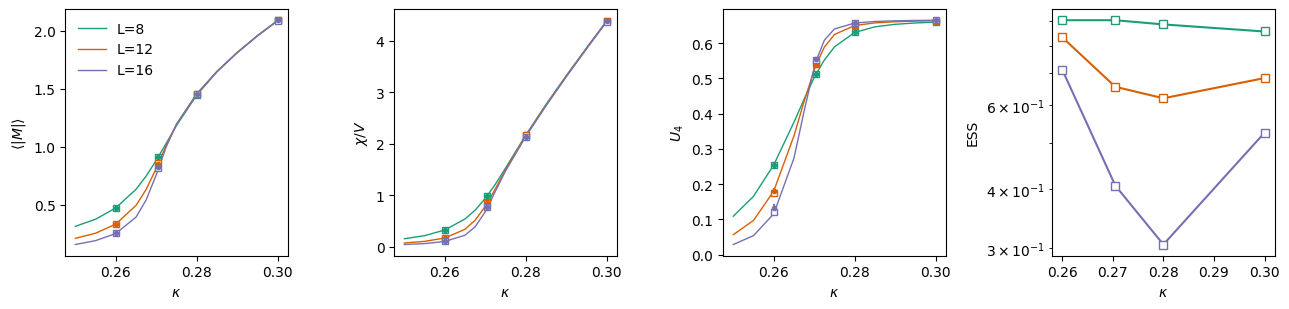

In [6]:
COL = {8: '#1b9e77', 12: '#d95f02', 16: '#7570b3'}
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
for L in LS:
    ks = sorted(v['kappa'] for v in REF.values() if v['L'] == L)
    for q, key in enumerate(KEYS):
        h = np.array([REF[f'L{L}_k{k}'][key] for k in ks])
        ax[q].plot(ks, h[:, 0], '-', color=COL[L], lw=1, label=f'L={L}' if q == 0 else None)
        rs = [r for r in results if r['L'] == L]
        kk = [r['kappa'] for r in rs]
        ax[q].errorbar(kk, [r['IS'][0][q] for r in rs], [r['IS'][1][q] for r in rs], fmt='s', mfc='white', color=COL[L], ms=4)
        ax[q].errorbar(kk, [r['IMH'][0][q] for r in rs], [r['IMH'][1][q] for r in rs], fmt='o', color=COL[L], ms=3)
    rs = [r for r in results if r['L'] == L]
    ax[3].semilogy([r['kappa'] for r in rs], [r['ESS'] for r in rs], 's-', mfc='white', color=COL[L])
for a, lab in zip(ax, [r'$\langle|M|\rangle$', r'$\chi/V$', r'$U_4$', 'ESS']):
    a.set_xlabel(r'$\kappa$'); a.set_ylabel(lab)
ax[0].legend(frameon=False)
fig.tight_layout()
plt.show()